 2.3. Класифікація логістичною регресією

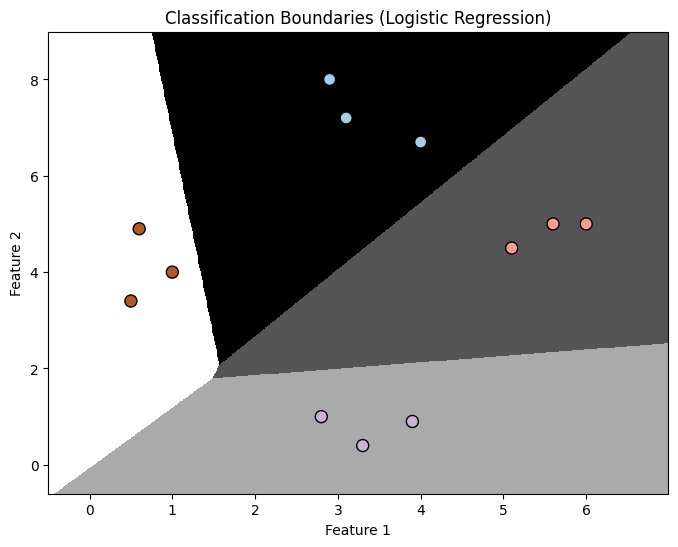

In [4]:
import numpy as np
from sklearn import linear_model
import matplotlib.pyplot as plt

def visualize_classifier(classifier, X, y):
    min_x, max_x = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    min_y, max_y = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0

    mesh_step_size = 0.01

    x_vals, y_vals = np.meshgrid(np.arange(min_x, max_x, mesh_step_size),
                                 np.arange(min_y, max_y, mesh_step_size))

    output = classifier.predict(np.c_[x_vals.ravel(), y_vals.ravel()])
    output = output.reshape(x_vals.shape)

    plt.figure(figsize=(8, 6))
    plt.pcolormesh(x_vals, y_vals, output, cmap=plt.cm.gray, shading='auto')
    plt.scatter(X[:, 0], X[:, 1], c=y, s=75, edgecolors='black', linewidth=1, cmap=plt.cm.Paired)

    plt.xlim(x_vals.min(), x_vals.max())
    plt.ylim(y_vals.min(), y_vals.max())
    plt.title('Classification Boundaries (Logistic Regression)')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()

X = np.array([
    [3.1, 7.2], [4.0, 6.7], [2.9, 8.0],
    [5.1, 4.5], [6.0, 5.0], [5.6, 5.0],
    [3.3, 0.4], [3.9, 0.9], [2.8, 1.0],
    [0.5, 3.4], [1.0, 4.0], [0.6, 4.9]
])

y = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3])

classifier = linear_model.LogisticRegression(solver='liblinear', C=1)

classifier.fit(X, y)

visualize_classifier(classifier, X, y)

2.4. Класифікація наївним байєсівським класифікатором


Accuracy of Naive Bayes classifier = 95.5 %


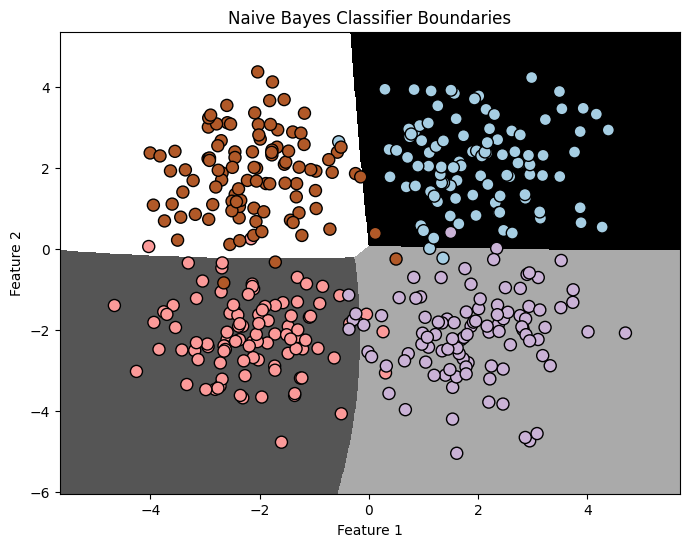

Accuracy of the new classifier = 91.25 %


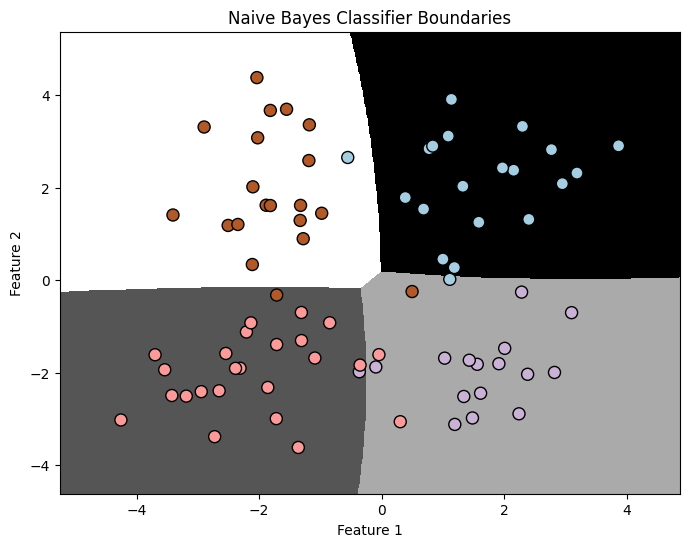

Accuracy: 95.25%
Precision: 95.32%
Recall: 95.25%
F1: 95.25%


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split, cross_val_score

def visualize_classifier(classifier, X, y):
    min_x, max_x = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    min_y, max_y = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    mesh_step_size = 0.01

    x_vals, y_vals = np.meshgrid(np.arange(min_x, max_x, mesh_step_size),
                                 np.arange(min_y, max_y, mesh_step_size))

    output = classifier.predict(np.c_[x_vals.ravel(), y_vals.ravel()])
    output = output.reshape(x_vals.shape)

    plt.figure(figsize=(8, 6))
    plt.pcolormesh(x_vals, y_vals, output, cmap=plt.cm.gray, shading='auto')
    plt.scatter(X[:, 0], X[:, 1], c=y, s=75, edgecolors='black', linewidth=1, cmap=plt.cm.Paired)

    plt.xlim(x_vals.min(), x_vals.max())
    plt.ylim(y_vals.min(), y_vals.max())
    plt.title('Naive Bayes Classifier Boundaries')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()

input_file = 'data_multivar_nb.txt'
try:
    data = np.loadtxt(input_file, delimiter=',')
except OSError:
    np.random.seed(0)
    c1 = np.random.randn(100, 2) + [2, 2]
    c2 = np.random.randn(100, 2) + [-2, -2]
    c3 = np.random.randn(100, 2) + [2, -2]
    c4 = np.random.randn(100, 2) + [-2, 2]
    X_gen = np.vstack((c1, c2, c3, c4))
    y_gen = np.array([0]*100 + [1]*100 + [2]*100 + [3]*100)
    data = np.hstack((X_gen, y_gen.reshape(-1, 1)))

X, y = data[:, :-1], data[:, -1]

classifier = GaussianNB()
classifier.fit(X, y)

y_pred = classifier.predict(X)
accuracy = 100.0 * (y == y_pred).sum() / X.shape[0]
print("Accuracy of Naive Bayes classifier =", round(accuracy, 2), "%")

visualize_classifier(classifier, X, y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=3)

classifier_new = GaussianNB()
classifier_new.fit(X_train, y_train)
y_test_pred = classifier_new.predict(X_test)

accuracy_new = 100.0 * (y_test == y_test_pred).sum() / X_test.shape[0]
print("Accuracy of the new classifier =", round(accuracy_new, 2), "%")

visualize_classifier(classifier_new, X_test, y_test)

num_folds = 3

accuracy_values = cross_val_score(classifier, X, y, scoring='accuracy', cv=num_folds)
print("Accuracy: " + str(round(100 * accuracy_values.mean(), 2)) + "%")

precision_values = cross_val_score(classifier, X, y, scoring='precision_weighted', cv=num_folds)
print("Precision: " + str(round(100 * precision_values.mean(), 2)) + "%")

recall_values = cross_val_score(classifier, X, y, scoring='recall_weighted', cv=num_folds)
print("Recall: " + str(round(100 * recall_values.mean(), 2)) + "%")

f1_values = cross_val_score(classifier, X, y, scoring='f1_weighted', cv=num_folds)
print("F1: " + str(round(100 * f1_values.mean(), 2)) + "%")

2.5. Вивчення метрик якості класифікації

--- Scores with threshold = 0.5 ---
Accuracy RF:  0.876
Recall RF:    1.000
Precision RF: 0.799
F1 RF:        0.888

--- Scores with threshold = 0.25 ---
Accuracy RF:  0.560
Recall RF:    1.000
Precision RF: 0.529
F1 RF:        0.692

AUC RF: 0.970
AUC LR: 0.877


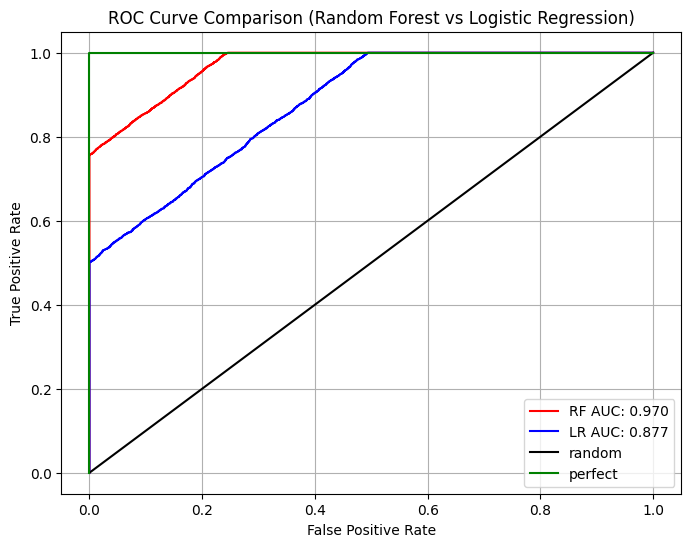

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, accuracy_score, recall_score,
                             precision_score, f1_score, roc_curve, roc_auc_score)

try:
    df = pd.read_csv('data_metrics.csv')
except FileNotFoundError:

    np.random.seed(42)
    n = 15758
    actual = np.random.binomial(1, 0.5, n)
    rf_prob = np.clip(actual * 0.3 + np.random.uniform(0.2, 0.6, n), 0, 1)
    lr_prob = np.clip(actual * 0.2 + np.random.uniform(0.2, 0.6, n), 0, 1)
    df = pd.DataFrame({'actual_label': actual, 'model_RF': rf_prob, 'model_LR': lr_prob})

df['predicted_RF'] = (df.model_RF >= 0.5).astype('int')
df['predicted_LR'] = (df.model_LR >= 0.5).astype('int')

def find_TP(y_true, y_pred):
    return sum((y_true == 1) & (y_pred == 1))

def find_FN(y_true, y_pred):
    return sum((y_true == 1) & (y_pred == 0))

def find_FP(y_true, y_pred):
    return sum((y_true == 0) & (y_pred == 1))

def find_TN(y_true, y_pred):
    return sum((y_true == 0) & (y_pred == 0))

def find_conf_matrix_values(y_true, y_pred):
    TP = find_TP(y_true, y_pred)
    FN = find_FN(y_true, y_pred)
    FP = find_FP(y_true, y_pred)
    TN = find_TN(y_true, y_pred)
    return TP, FN, FP, TN

def yakymenko_confusion_matrix(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return np.array([[TN, FP], [FN, TP]])


assert np.array_equal(yakymenko_confusion_matrix(df.actual_label.values, df.predicted_RF.values),
                      confusion_matrix(df.actual_label.values, df.predicted_RF.values)), 'Matrix failed on RF'
assert np.array_equal(yakymenko_confusion_matrix(df.actual_label.values, df.predicted_LR.values),
                      confusion_matrix(df.actual_label.values, df.predicted_LR.values)), 'Matrix failed on LR'

def yakymenko_accuracy_score(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return (TP + TN) / (TP + TN + FP + FN)

def yakymenko_recall_score(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return TP / (TP + FN)

def yakymenko_precision_score(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return TP / (TP + FP)

def yakymenko_f1_score(y_true, y_pred):
    recall = yakymenko_recall_score(y_true, y_pred)
    precision = yakymenko_precision_score(y_true, y_pred)
    return 2 * (precision * recall) / (precision + recall)


assert np.isclose(yakymenko_accuracy_score(df.actual_label.values, df.predicted_RF.values),
                   accuracy_score(df.actual_label.values, df.predicted_RF.values)), 'Accuracy failed on RF'

assert np.isclose(yakymenko_recall_score(df.actual_label.values, df.predicted_RF.values),
                   recall_score(df.actual_label.values, df.predicted_RF.values)), 'Recall failed on RF'

assert np.isclose(yakymenko_precision_score(df.actual_label.values, df.predicted_RF.values),
                   precision_score(df.actual_label.values, df.predicted_RF.values)), 'Precision failed on RF'

assert np.isclose(yakymenko_f1_score(df.actual_label.values, df.predicted_RF.values),
                   f1_score(df.actual_label.values, df.predicted_RF.values)), 'F1 failed on RF'

print(' Scores with threshold = 0.5 ')
print('Accuracy RF:  %.3f' % yakymenko_accuracy_score(df.actual_label.values, df.predicted_RF.values))
print('Recall RF:    %.3f' % yakymenko_recall_score(df.actual_label.values, df.predicted_RF.values))
print('Precision RF: %.3f' % yakymenko_precision_score(df.actual_label.values, df.predicted_RF.values))
print('F1 RF:        %.3f' % yakymenko_f1_score(df.actual_label.values, df.predicted_RF.values))

print('\n Scores with threshold = 0.25 ')
rf_thresh_025 = (df.model_RF >= 0.25).astype('int').values
print('Accuracy RF:  %.3f' % yakymenko_accuracy_score(df.actual_label.values, rf_thresh_025))
print('Recall RF:    %.3f' % yakymenko_recall_score(df.actual_label.values, rf_thresh_025))
print('Precision RF: %.3f' % yakymenko_precision_score(df.actual_label.values, rf_thresh_025))
print('F1 RF:        %.3f' % yakymenko_f1_score(df.actual_label.values, rf_thresh_025))

fpr_RF, tpr_RF, thresholds_RF = roc_curve(df.actual_label.values, df.model_RF.values)
fpr_LR, tpr_LR, thresholds_LR = roc_curve(df.actual_label.values, df.model_LR.values)

auc_RF = roc_auc_score(df.actual_label.values, df.model_RF.values)
auc_LR = roc_auc_score(df.actual_label.values, df.model_LR.values)

print('\nAUC RF: %.3f' % auc_RF)
print('AUC LR: %.3f' % auc_LR)

plt.figure(figsize=(8, 6))
plt.plot(fpr_RF, tpr_RF, 'r-', label='RF AUC: %.3f' % auc_RF)
plt.plot(fpr_LR, tpr_LR, 'b-', label='LR AUC: %.3f' % auc_LR)
plt.plot([0, 1], [0, 1], 'k-', label='random')
plt.plot([0, 0, 1, 1], [0, 1, 1, 1], 'g-', label='perfect')
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison (Random Forest vs Logistic Regression)')
plt.grid(True)
plt.show()

2.6. Класифікація даних за допомогою машини опорних векторі


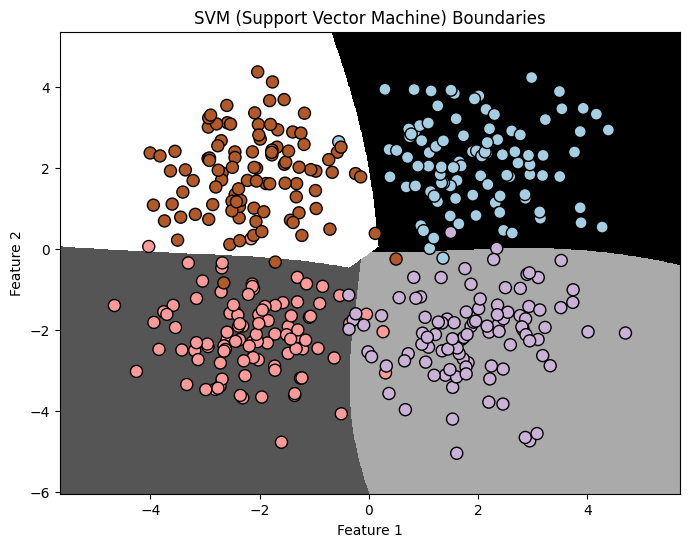

Показники якості SVM (Support Vector Machine) 
Accuracy:  95.50%
Precision: 95.55%
Recall:    95.50%
F1 Score:  95.50%


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

def visualize_classifier(classifier, X, y):
    min_x, max_x = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    min_y, max_y = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    mesh_step_size = 0.01

    x_vals, y_vals = np.meshgrid(np.arange(min_x, max_x, mesh_step_size),
                                 np.arange(min_y, max_y, mesh_step_size))

    output = classifier.predict(np.c_[x_vals.ravel(), y_vals.ravel()])
    output = output.reshape(x_vals.shape)

    plt.figure(figsize=(8, 6))
    plt.pcolormesh(x_vals, y_vals, output, cmap=plt.cm.gray, shading='auto')
    plt.scatter(X[:, 0], X[:, 1], c=y, s=75, edgecolors='black', linewidth=1, cmap=plt.cm.Paired)

    plt.xlim(x_vals.min(), x_vals.max())
    plt.ylim(y_vals.min(), y_vals.max())
    plt.title('SVM (Support Vector Machine) Boundaries')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()

input_file = 'data_multivar_nb.txt'
try:
    data = np.loadtxt(input_file, delimiter=',')
except OSError:
    np.random.seed(0)
    c1 = np.random.randn(100, 2) + [2, 2]
    c2 = np.random.randn(100, 2) + [-2, -2]
    c3 = np.random.randn(100, 2) + [2, -2]
    c4 = np.random.randn(100, 2) + [-2, 2]
    X_gen = np.vstack((c1, c2, c3, c4))
    y_gen = np.array([0]*100 + [1]*100 + [2]*100 + [3]*100)
    data = np.hstack((X_gen, y_gen.reshape(-1, 1)))

X, y = data[:, :-1], data[:, -1]

svm_classifier = SVC(kernel='rbf', C=1.0)
svm_classifier.fit(X, y)

visualize_classifier(svm_classifier, X, y)

num_folds = 3

acc_svm = cross_val_score(svm_classifier, X, y, scoring='accuracy', cv=num_folds).mean()
prec_svm = cross_val_score(svm_classifier, X, y, scoring='precision_weighted', cv=num_folds).mean()
rec_svm = cross_val_score(svm_classifier, X, y, scoring='recall_weighted', cv=num_folds).mean()
f1_svm = cross_val_score(svm_classifier, X, y, scoring='f1_weighted', cv=num_folds).mean()

print("Показники якості SVM (Support Vector Machine) ")
print(f"Accuracy:  {acc_svm * 100:.2f}%")
print(f"Precision: {prec_svm * 100:.2f}%")
print(f"Recall:    {rec_svm * 100:.2f}%")
print(f"F1 Score:  {f1_svm * 100:.2f}%")